# 04 逻辑回归与分类评估


本篇对应课程目录中的 `04-线性回归`，但该目录的教师讲义和课件实际内容是《逻辑回归》。逻辑回归虽然名字里有“回归”，训练目标却是分类：它把线性模型的分数映射成概率，再根据任务需要选择分类阈值。

学习路线：

1. 从 sigmoid、概率和极大似然理解模型为什么能输出分类概率；
2. 掌握二元交叉熵、正则化和 `LogisticRegression` 的常用 API；
3. 完成癌症分类案例；
4. 用混淆矩阵、准确率、精确率、召回率、F1、ROC/AUC 评价模型；
5. 了解电信客户流失案例中的编码、交叉验证和阈值选择。

> 本笔记的代码均放在 Markdown 代码块中，复制到 Python 文件或代码单元即可运行。课程网盘中的 CSV 需要放到自己的数据目录；本篇另外提供一个不依赖课程 CSV 的离线示例。

资料来源：[机器学习课程网盘](https://pan.baidu.com/s/1NmWli9KoAeYtlpXTzhw-Jg?pwd=1234)，提取码 `1234`。本篇依据第 04 个目录的 `01-讲义/逻辑回归.pptx` 和 `02-笔记/逻辑回归.md` 整理，补充了指标手算、数据泄漏处理及新版 API 说明。所有图片均为 Notebook 内嵌附件。

## 1. 逻辑回归解决什么问题

逻辑回归适合目标只有两个状态的任务，例如：是否患病、是否流失、是否点击、是否违约。先把业务正例明确下来，例如医疗筛查中把“恶性”定义为 `1`，再让模型学习“输入特征属于正例的概率”。

正例不是由算法自动决定的。少数类也不是默认正例；在 scikit-learn 中，概率列的顺序由 `model.classes_` 决定。

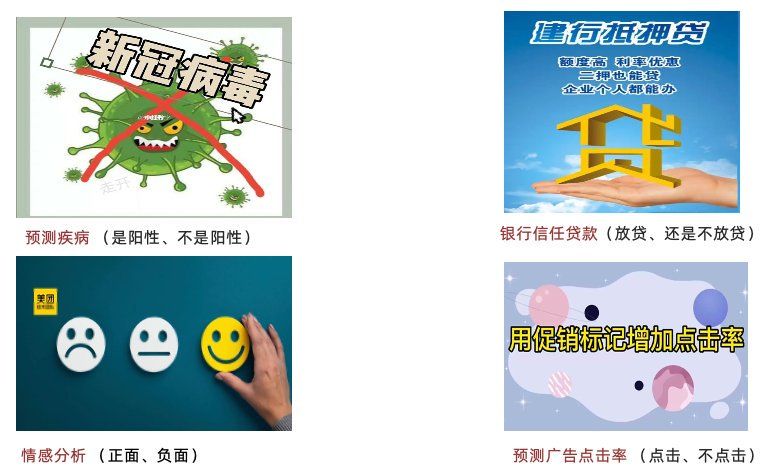

*原课用多个二分类场景说明逻辑回归的适用范围。*


## 2. sigmoid：把线性分数变成概率

先计算线性分数：

$$z=w^\mathsf{T}x+b$$

再通过 sigmoid 函数：

$$\sigma(z)=\frac{1}{1+e^{-z}}$$

当 $z$ 很大时，概率接近 1；当 $z$ 很小时，概率接近 0；$z=0$ 时概率恰好为 0.5。输出始终在 $(0,1)$ 内，因此可以解释为正例概率，但概率解释仍依赖数据、模型和校准质量。

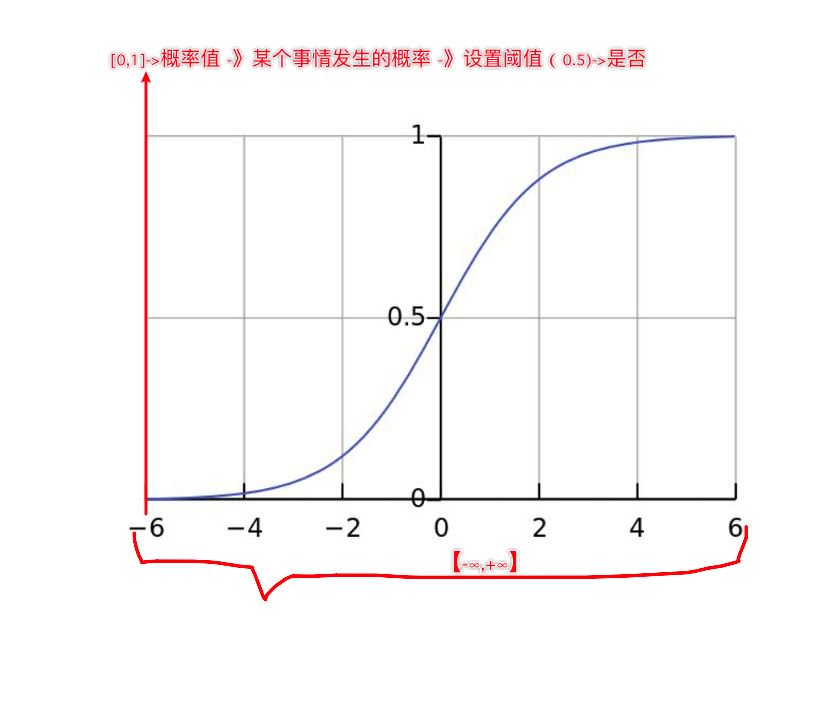

*sigmoid 把任意实数压缩到 0 和 1 之间。*


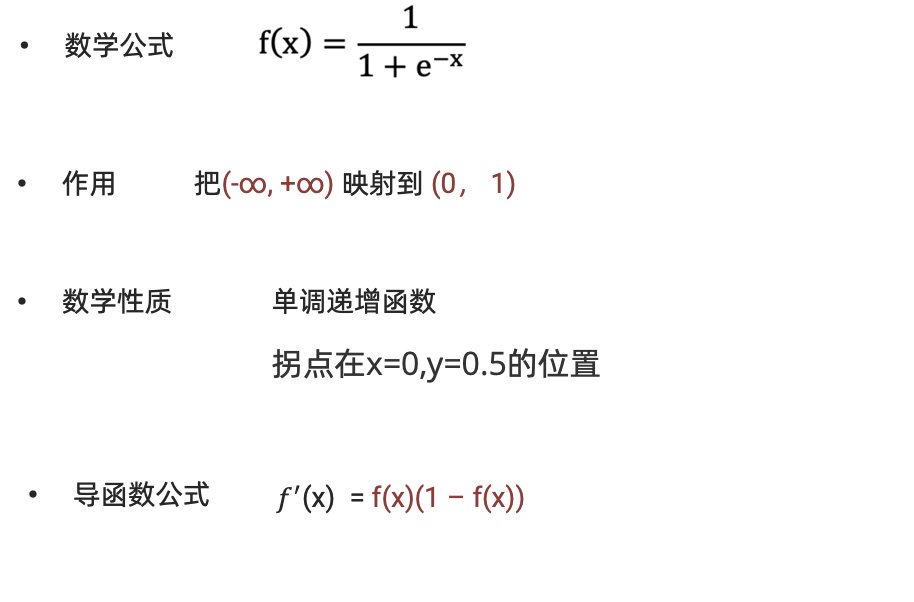

*sigmoid 的导数为 $\sigma(z)(1-\sigma(z))$，在反向传播或梯度推导中会用到。*


### 2.1 概率、优势比与 logit

若 $p=P(y=1\mid x)$，则优势比（odds）为 $p/(1-p)$，logit 是它的对数：

$$\operatorname{logit}(p)=\log\frac{p}{1-p}=w^\mathsf{T}x+b$$

所以逻辑回归假设的是：**正例对负例的对数优势比与特征线性相关**。它并没有假设原始目标值与特征做普通线性回归。

例如 $p=0.8$ 时，优势比是 4，logit 是 $\ln4\approx1.386$。在其他变量保持不变时，某个特征增加一个单位，会令 logit 增加相应的系数；正系数提高正例的优势比，负系数降低它。经过标准化后，“一个单位”是一个标准差，而不是原始量纲，解释系数时要注明这一点。

```python
import numpy as np
from scipy.special import expit

z = np.array([-2.0, 0.0, 2.0])
print(np.round(expit(z), 6))  # [0.119203 0.5 0.880797]
```


## 3. 极大似然：从硬币例子到分类损失

极大似然的想法是：在观测数据已经出现的前提下，寻找一组参数，使这些观测出现的可能性最大。假设硬币正面概率为 $\theta$，投掷 6 次得到 4 次正面、2 次反面，则

$$L(\theta)=\theta^4(1-\theta)^2$$

取对数后，乘积变成求和：

$$\ell(\theta)=4\log\theta+2\log(1-\theta)$$

对它求导并令导数为 0，可得 $\hat\theta=4/6=2/3$。对数不会改变最大值的位置，却能让计算更稳定。

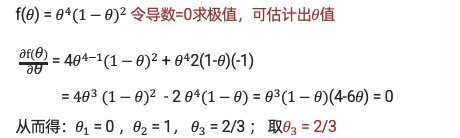

*6 次投掷中 4 次正面、2 次反面时，似然最大点是 $	heta=2/3$。*


### 3.1 伯努利似然与二元交叉熵

对第 $i$ 个样本，真实标签 $y_i\in\{0,1\}$，模型给出正例概率 $p_i$。伯努利条件似然为：

$$L=\prod_{i=1}^{m}p_i^{y_i}(1-p_i)^{1-y_i}$$

最大化对数似然，等价于最小化平均负对数似然，也就是二元交叉熵（BCE）：

$$J(w,b)=-\frac{1}{m}\sum_{i=1}^{m}\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right]$$

当真实标签是 1 时，$p$ 越小损失越大；当真实标签是 0 时，$p$ 越大损失越大。不要把似然理解成“所有预测标签恰好正确的概率”，它是给定参数下观测标签的联合条件概率。

**损失也可以手算。** 假设三个样本的真实标签为 `[0, 1, 1]`、预测概率为 `[0.4, 0.68, 0.7]`，单样本损失分别约为 `0.510826、0.385662、0.356675`，平均 BCE 约为 `0.417721`。这里使用给定概率计算，不把原图中出现的近似数字当成执行结果。

```python
import numpy as np

y = np.array([0, 1, 1])
p = np.array([0.4, 0.68, 0.7])
loss = -(y * np.log(p) + (1 - y) * np.log1p(-p))
print(loss, loss.mean())
```


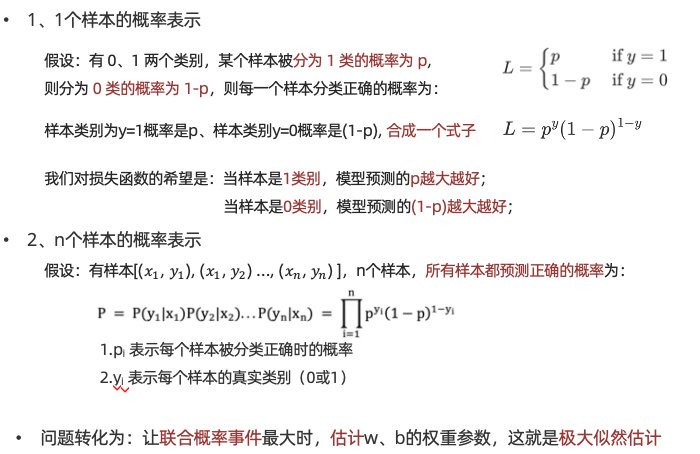

*正例和负例统一写进 $p^y(1-p)^{1-y}$。*


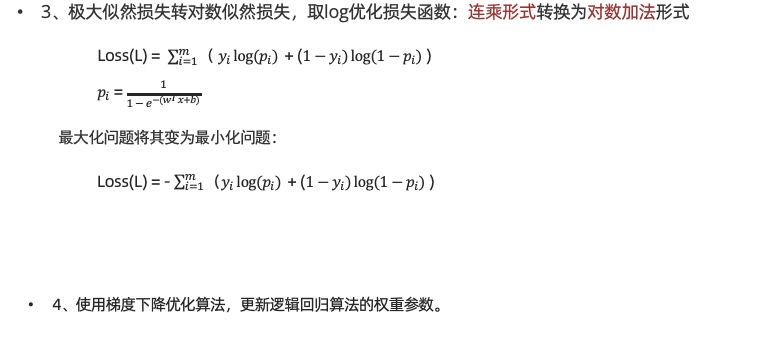

*取对数、取负号并求平均后得到训练时最小化的损失。*


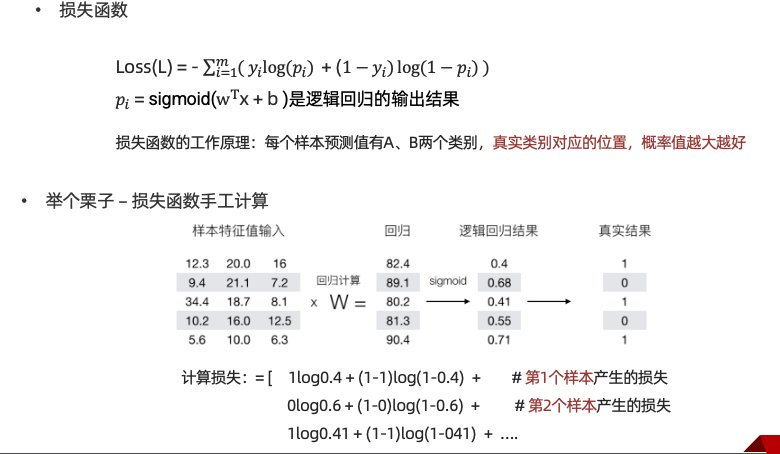

*预测越自信却越错误，交叉熵惩罚越大。*


### 3.2 梯度与数值稳定

把 $p=\sigma(Xw+b)$ 写成向量形式，BCE 对参数的梯度为：

$$\nabla_wJ=\frac{1}{m}X^\mathsf{T}(p-y),\qquad
\frac{\partial J}{\partial b}=\frac{1}{m}\sum_{i=1}^{m}(p_i-y_i)$$

实际代码中，直接先计算 `exp(-z)` 再取 `log` 可能在极端分数下溢出或溢出。稳定的单样本写法是：

$$\operatorname{BCE}(z,y)=\log(1+e^z)-yz=\operatorname{logaddexp}(0,z)-yz$$

其中 `np.logaddexp(0, z)` 能降低数值溢出的风险。

这与前一篇线性回归有一个容易记住的联系：两者的梯度都出现“预测减真实”，但逻辑回归的预测是概率，损失是交叉熵。没有正则化时，完全可分的数据可能使参数越来越大，无法得到有限的极大似然解；正则化能限制参数并改善稳定性。

```python
import numpy as np
from scipy.special import expit

X = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
y = np.array([0.0, 1.0, 1.0])
w = np.array([0.2, -0.1])
b = 0.0
z = X @ w + b
loss = np.mean(np.logaddexp(0, z) - y * z)
grad_w = X.T @ (expit(z) - y) / len(y)
grad_b = np.mean(expit(z) - y)
print(loss, grad_w, grad_b)
```

可以用小扰动的有限差分检查这组梯度，正式训练通常直接交给 sklearn 的优化器。


### 3.3 模型、阈值与决策边界

训练阶段学习的是 $w,b$；预测阶段先得到概率，再按阈值 $t$ 输出标签：

$$\hat y=\mathbb{1}[p\ge t]$$

当 $t=0.5$ 时，决策边界满足 $z=0$，也就是 $w^\mathsf{T}x+b=0$。阈值不一定要固定为 0.5：漏掉正例的代价很高时，通常会考虑降低阈值；误报代价高时，可能提高阈值。阈值应在独立验证集或交叉验证的 out-of-fold 预测上选择，不能反复用测试集调到最好。

本篇手工阈值代码统一采用 `p >= t`。sklearn 的二分类 `predict()` 在分数恰好为 0 时可能选择 `classes_[0]`，因此精确相等的边界样本可能与本篇规则有一点差异。多项式特征可令原始特征空间的边界变弯，但仍需用验证集判断是否过拟合。


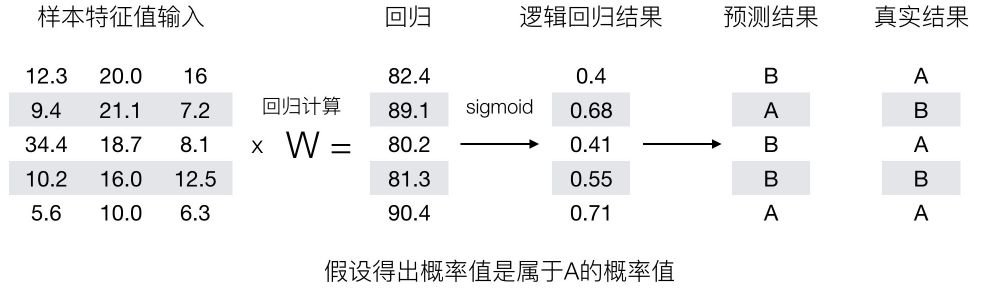

*原图是分步示意，其中的中间概率是给定教学值，不能把表中的线性分数直接当作 sigmoid 的精确计算结果。*


## 4. `LogisticRegression` API 与正则化

常用写法：

```python
from sklearn.linear_model import LogisticRegression

# 假设已经切分好 X_train/X_test/y_train
model = LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000)
model.fit(X_train, y_train)
prob = model.predict_proba(X_test)
pred = model.predict(X_test)
```

- `solver` 是数值优化方法。`lbfgs` 是中小规模、L2 正则的常用起点；`liblinear` 适合较小数据的二分类；`saga` 可处理 L1、L2 和 Elastic Net，并支持稀疏特征。
- `C` 是正则化强度的倒数：`C` 越小，正则化越强；这和 Ridge 中的 `alpha` 方向相反。
- 当前 scikit-learn 1.8 起，`penalty` 参数已弃用，计划在 1.10 移除。跨版本代码可直接使用默认 L2；新版若需要 L1，可用 `solver="saga", l1_ratio=1.0`。
- `class_weight="balanced"` 会按类别频率反比加权训练，不会自动把少数类改成正例，也不保证准确率或 AUC 一定提高。

较老课程资料中的 `penalty="l1"`、`penalty="l2"` 仍常见于旧版本。迁移到新版本时先查看本机签名和版本，不要盲目复制旧参数。

### 4.1 正则化与优化方法速查

| 新版配置 | 作用 | 常用 solver |
|---|---|---|
| `l1_ratio=0.0`（默认） | L2，整体压小系数 | `lbfgs`、`newton-cg`、`newton-cholesky`、`sag`、`saga` |
| `l1_ratio=1.0` | L1，可产生零系数 | `saga`；`liblinear` 也支持二分类 L1 |
| `0 < l1_ratio < 1` | Elastic Net，混合 L1 与 L2 | `saga` |
| `C=np.inf` | 不做正则化（新版） | 需核对 solver 的兼容性 |

1.7 及以前的写法是 `penalty='l2'`、`'l1'`、`'elasticnet'` 或 `None`。`sag/saga` 对特征尺度敏感，应先缩放；优化器的速度还受样本数、特征数、稀疏度影响，不能只凭名称保证快慢。出现收敛警告时，先检查数据和尺度，再考虑增加 `max_iter` 或调整 solver。

```python
import sklearn
from sklearn.linear_model import LogisticRegression

print(sklearn.__version__)
# 以下为 sklearn 1.8+ 的 L1 配置；旧版本需使用 penalty='l1'
l1_model = LogisticRegression(
    solver='saga', l1_ratio=1.0, C=1.0, max_iter=10000, random_state=21
)
```


## 5. 癌症分类案例：先明确数据和标签

课程原始 `breast-cancer-wisconsin.csv` 的说明是：699 条样本、ID 加 9 个医学特征，最后一列为类别；类别 2 表示良性，4 表示恶性，缺失值用 `?` 表示。原课的做法是删除缺失行，再把恶性编码为正例。

推荐先明确约定：

- `y = (Class == 4).astype(int)`，恶性为 1、良性为 0；
- 删除 ID，不把它作为特征；
- 缺失值处理只在训练集拟合，实际项目优先使用 `Pipeline`；
- 切分时使用 `stratify=y` 保持类别比例；这比原课未分层切分更稳健。

若网盘 CSV 尚未下载，可以使用下面的 `load_breast_cancer` 离线示例练习流程。它是 sklearn 自带的另一个数据集（569 条、30 个特征），不等同于课程的 699 条、9 个特征数据，不能混用两者的样本统计。

### 5.1 课程 CSV 的参考流程

```python
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

raw = pd.read_csv("data/breast-cancer-wisconsin.csv", na_values=["?"])
raw = raw.dropna().copy()
if not raw["Class"].astype(int).isin([2, 4]).all():
    raise ValueError("Class 应只包含课程编码 2/4，请核对数据")
X = raw.iloc[:, 1:-1].astype(float)       # 去掉 ID 和最后的 Class
# 课程编码：2=良性(0)，4=恶性(1)
y = (raw["Class"].astype(int) == 4).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=21, stratify=y
)
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000)
)
model.fit(X_train, y_train)
prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)
from sklearn.metrics import classification_report, roc_auc_score
print(classification_report(y_test, pred, labels=[0, 1],
                            target_names=["良性", "恶性"], zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, prob))
```

`na_values=["?"]` 会在读取时把问号解析为缺失值；NumPy 2 中应使用 `np.nan`，不要继续写已移除的 `np.NaN`。

上述代码需要课程 CSV，读取后还应检查 `raw.shape`、列名和各类别数量。本轮已核对教师文件和课程说明，但未取得该 CSV，因此不提供该文件的实跑成绩。删除缺失行方便课堂练习；若不想丢弃样本，先切分，再在 Pipeline 内加入 `SimpleImputer(strategy="median")`。


### 5.2 不依赖网盘 CSV 的完整离线示例

下面的代码可直接运行，用 sklearn 自带数据集演示同一套步骤。恶性原标签是 0，因此先显式重编码为正例 1，再定位概率列。

```python
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

cancer = load_breast_cancer(as_frame=True)
X = cancer.data
# sklearn 原标签：0=malignant，1=benign；把恶性作为业务正例
positive = (cancer.target == 0).astype(int)
X_cancer_train, X_cancer_test, y_cancer_train, y_cancer_test = train_test_split(
    X, positive, test_size=0.2, random_state=21, stratify=positive
)
cancer_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000)
)
cancer_model.fit(X_cancer_train, y_cancer_train)
cancer_prob = cancer_model.predict_proba(X_cancer_test)[:, 1]
cancer_pred = (cancer_prob >= 0.5).astype(int)
print("accuracy:", accuracy_score(y_cancer_test, cancer_pred))
print(classification_report(
    y_cancer_test, cancer_pred, labels=[0, 1], target_names=["良性", "恶性"], zero_division=0
))
print("roc_auc:", roc_auc_score(y_cancer_test, cancer_prob))
```

### 5.3 离线示例实跑结果

本轮在 scikit-learn 1.9.1、NumPy 2.5.4、pandas 3.0.6 上运行上述代码，训练集 455 条，测试集 114 条（72 良性、42 恶性）。恶性为正例、阈值为 0.5：

| 指标 | 结果 |
|---|---:|
| Accuracy | 0.973684 |
| 恶性 Precision | 0.975610 |
| 恶性 Recall | 0.952381 |
| 恶性 F1 | 0.963855 |
| ROC-AUC | 0.996362 |

混淆矩阵为 $\begin{bmatrix}71&1\\2&40\end{bmatrix}$（行真实、列预测，标签顺序 `[0,1]`）：2 个恶性漏报、1 个良性误报。以上是 sklearn 内置数据集的教学结果，不是课程 CSV 的成绩，也不能用于真实医疗决策。不同依赖版本的末尾数值可能略有差异。

## 6. 混淆矩阵：先看四种结果

假设“恶性”为正例：

- **TP**：真实恶性，预测恶性；
- **FN**：真实恶性，预测良性，也叫漏报；
- **FP**：真实良性，预测恶性，也叫误报；
- **TN**：真实良性，预测良性。

使用 `confusion_matrix(..., labels=[0, 1])` 时，矩阵行是真实标签、列是预测标签，排列为：

$$\begin{bmatrix}TN&FP\FN&TP\end{bmatrix}$$

教师课件中的正例在前、矩阵顺序与 sklearn 默认排列不同。计算后 `ravel()` 前必须先固定 `labels`，否则很容易把 TP、TN 对调。

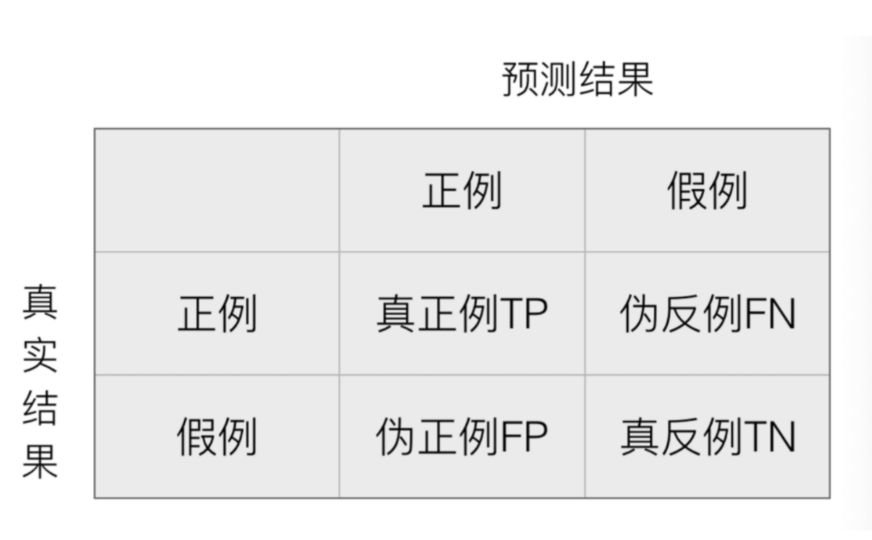

*原图按正例在前展示；使用 sklearn 时请显式指定标签顺序。*


### 6.1 模型 A 与模型 B

10 个样本中有 6 个恶性、4 个良性：

| 模型 | TP | FN | FP | TN | Accuracy | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| A | 3 | 3 | 0 | 4 | 0.70 | 1.00 | 0.50 | 0.667 |
| B | 6 | 0 | 3 | 1 | 0.70 | 0.667 | 1.00 | 0.800 |

两者准确率相同，但模型 A 不漏报的能力较弱，模型 B 会产生更多误报。哪个更好取决于业务代价：医疗筛查往往更关心漏报，资源有限的人工审核可能更关心误报。

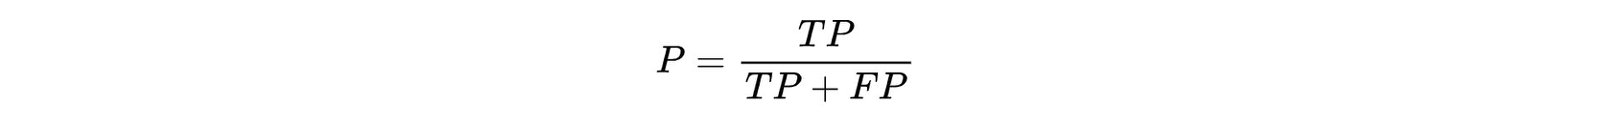

*精确率的分母是所有预测为正例的样本。*


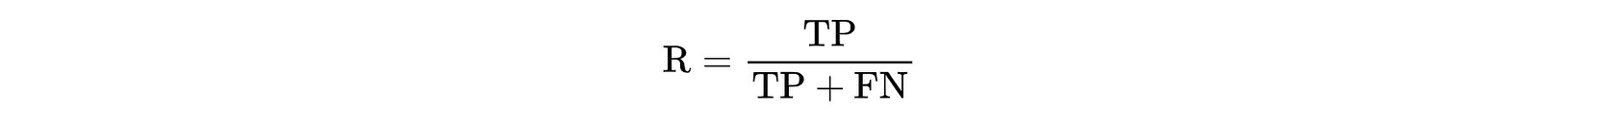

*召回率的分母是所有真实正例的样本。*


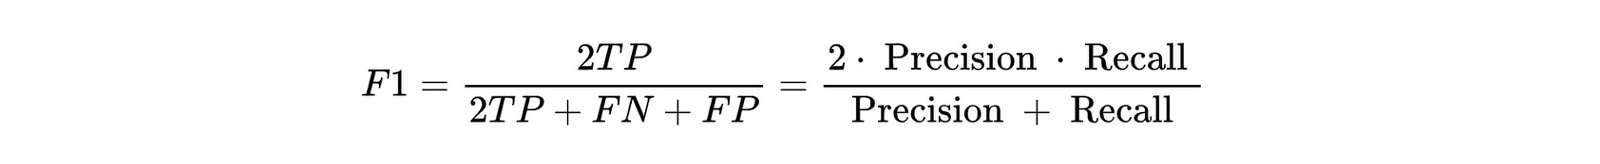

*F1 是精确率和召回率的调和平均。*


### 6.2 四个指标的公式和代码

$$\operatorname{accuracy}=\frac{TP+TN}{TP+TN+FP+FN}$$

$$\operatorname{precision}=\frac{TP}{TP+FP},\quad
\operatorname{recall}=\frac{TP}{TP+FN}$$

$$F1=\frac{2PR}{P+R}=\frac{2TP}{2TP+FP+FN}$$

```python
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)

y_true = [1]*6 + [0]*4       # 1=恶性，0=良性
y_pred_a = [1,1,1,0,0,0, 0,0,0,0]
y_pred_b = [1,1,1,1,1,1, 1,1,1,0]
for name, pred in [("A", y_pred_a), ("B", y_pred_b)]:
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    print(name, {"TN":tn, "FP":fp, "FN":fn, "TP":tp})
    print("accuracy", accuracy_score(y_true, pred))
    print("precision", precision_score(y_true, pred, pos_label=1, zero_division=0))
    print("recall", recall_score(y_true, pred, pos_label=1, zero_division=0))
    print("f1", f1_score(y_true, pred, pos_label=1, zero_division=0))
```

`zero_division=0` 只是对分母为 0 时的工程处理约定，并不表示该数学比值有定义。

### 6.3 准确率为什么可能会骗人

如果 100 个客户中只有 5 个会流失，一个“全部预测为不流失”的模型准确率有 95%，但流失召回率是 0。类别不平衡时，应至少同时查看正例的 precision、recall、F1，并结合 ROC-AUC 或 PR-AUC。指标没有脱离任务的绝对优劣，必须先说明正例和错误代价。

### 分类报告怎么看

`classification_report` 每行给一个类别的 precision、recall、F1 和 support（真实样本数）。这里把良性和恶性分别当作该行的正例来统计：

- `macro avg`：各类别等权平均，少数类差也会明显拉低结果；
- `weighted avg`：按各类别的真实样本数加权，容易受多数类主导；
- `accuracy`：整体预测正确率。

阅读报告时先看业务正例那一行，再看总体指标。类别权重改变的是训练损失，不会让所有指标自动变好；应比较同样的验证切分和同样的评分。


## 7. ROC 曲线与 AUC

ROC 曲线在不同阈值下记录：

$$TPR=\frac{TP}{TP+FN}=\operatorname{recall},\qquad
FPR=\frac{FP}{FP+TN}$$

横轴是 FPR，纵轴是 TPR。阈值从高到低移动，通常会把更多样本判为正例，曲线从 `(0,0)` 走向 `(1,1)`。左上角 `(0,1)` 表示当前数据上的理想排序；对角线附近相当于随机排序。

AUC 是 ROC 曲线下面积，衡量模型把随机正例排在随机负例前面的能力。它评价排序能力，不是某一个阈值的准确率，也不直接保证概率校准良好。测试集只有一个类别时，ROC-AUC 没有定义。

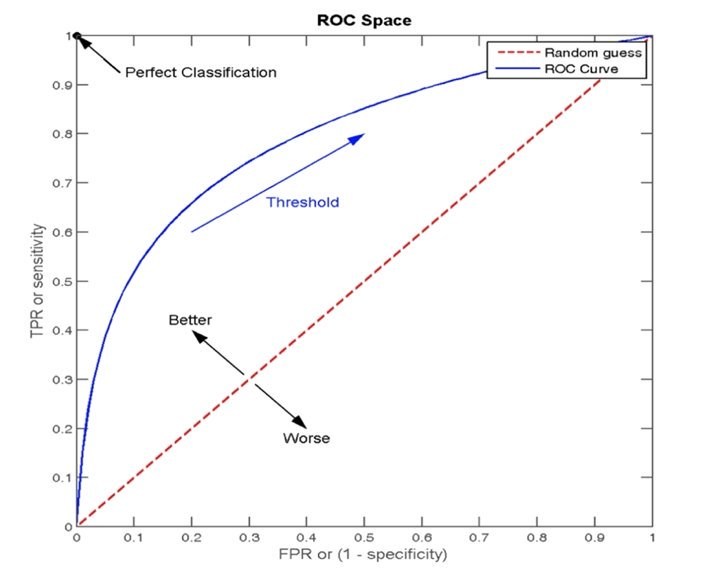

*横轴为假正例率 FPR，纵轴为真正例率 TPR。*


### 7.1 六个广告样本的手算

| 样本 | 实际点击 $y$ | 预测点击概率 |
|---:|---:|---:|
| 1 | 1 | 0.9 |
| 2 | 0 | 0.7 |
| 3 | 1 | 0.8 |
| 4 | 0 | 0.6 |
| 5 | 0 | 0.5 |
| 6 | 0 | 0.4 |

按概率从高到低排序为 1、3、2、4、5、6。阈值依次降到 0.9、0.8、0.7、0.6、0.5、0.4 时，ROC 点（含起点）为：

| 阈值区间动作 | FPR | TPR |
|---|---:|---:|
| 尚未预测正例 | 0 | 0 |
| 纳入样本 1 | 0 | 0.5 |
| 纳入样本 3 | 0 | 1 |
| 纳入样本 2 | 0.25 | 1 |
| 纳入样本 4 | 0.50 | 1 |
| 纳入样本 5 | 0.75 | 1 |
| 纳入样本 6 | 1 | 1 |

这里 AUC=1，说明这个小样本中所有正例都排在所有负例之前；若固定阈值 0.5，预测标签的准确率只有 3/6。这个例子正好说明排序指标和固定阈值指标回答的是不同问题。

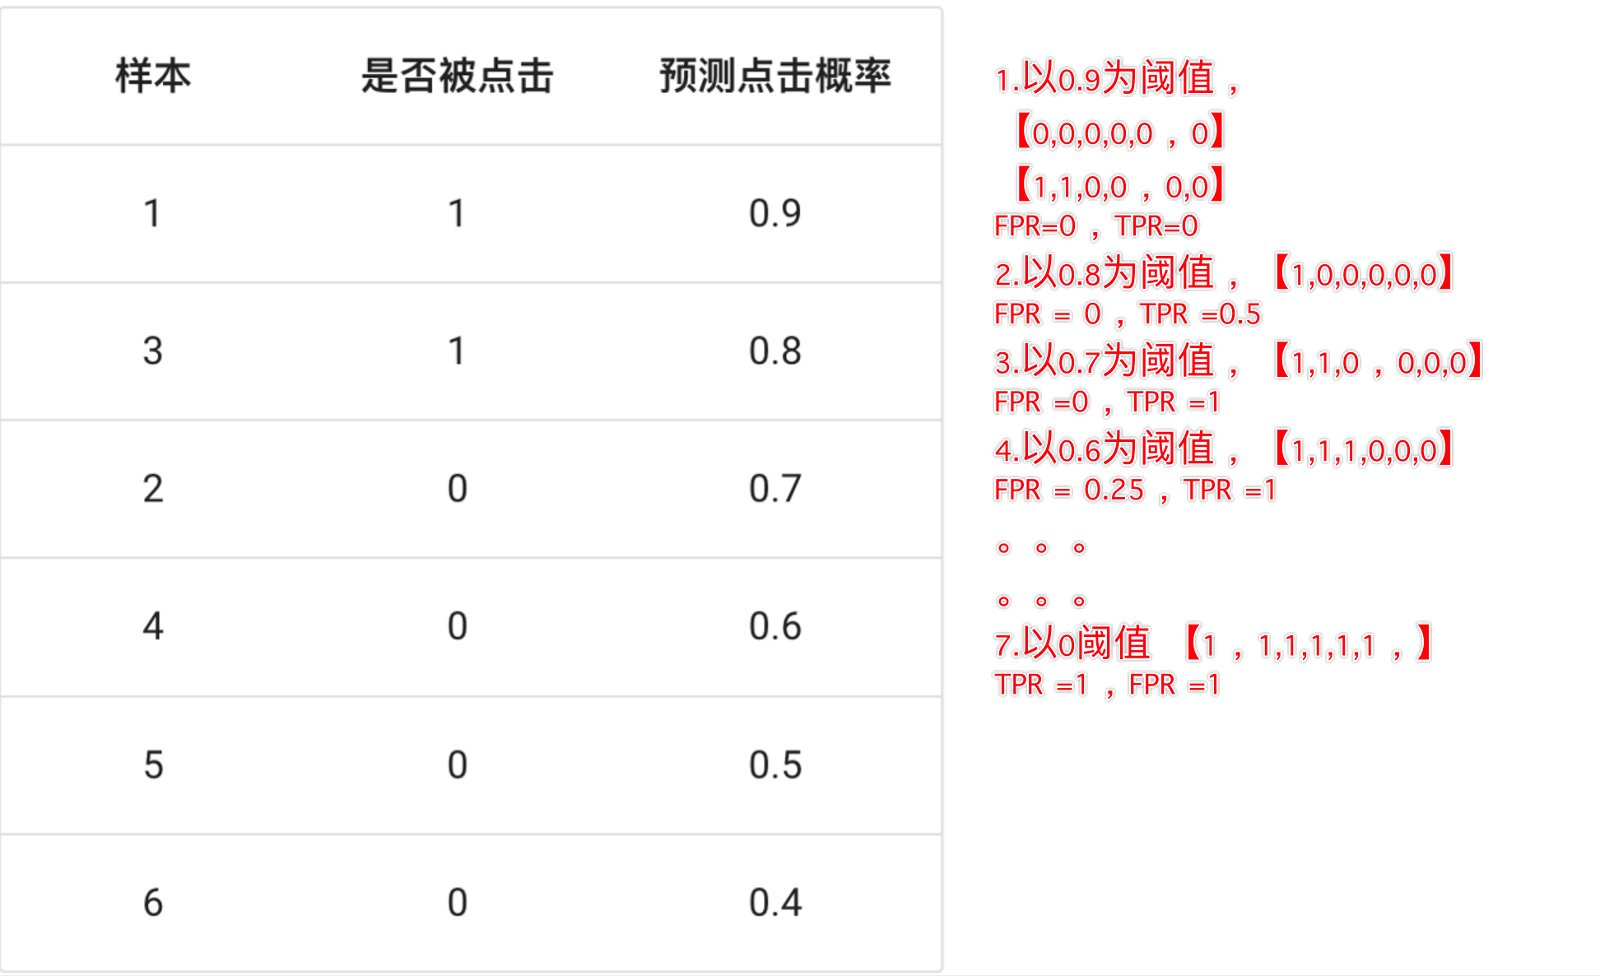

*原课图用于演示阈值变化；以本篇上表的重新核算结果为准。*


### 7.2 用概率或分数计算 AUC

`roc_auc_score` 的第二个参数应是连续概率或 `decision_function` 分数，而不是 `predict` 得到的硬标签。硬标签最多只保留一个阈值点，会丢掉排序信息。

```python
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score

y_true = np.array([1, 0, 1, 0, 0, 0])
y_score = np.array([0.9, 0.7, 0.8, 0.6, 0.5, 0.4])
fpr, tpr, thresholds = roc_curve(y_true, y_score, drop_intermediate=False)
print(np.c_[thresholds, fpr, tpr])
print("AUC:", roc_auc_score(y_true, y_score))

# 对 LogisticRegression：明确取业务正例的概率列
positive_label = 1
positive_col = np.flatnonzero(cancer_model.classes_ == positive_label)[0]
positive_prob = cancer_model.predict_proba(X_cancer_test)[:, positive_col]
auc = roc_auc_score(y_cancer_test, positive_prob)
```

若正例标签不是 1，先重编码，或使用 `classes_` 定位对应概率列。严重类别不平衡时可补充 `average_precision_score`（PR-AUC）观察正例检索质量。
AUC=1 只表示当前评估集完全排序正确，不保证未来样本完美；AUC<0.5 时先检查正例定义和概率列是否弄反，再检查模型。


## 8. 电信客户流失：从数据处理到评估

课程背景数据约 7043 行，目标字段是 `Churn`，教师示例中选取了 `Contract_Month`、`internet_other`、`PaymentElectronic` 三个处理后的字段。网盘 CSV 的真实列名应以 `df.columns` 为准，不能把这三个字段猜成所有 Telco 数据集都存在。

一个可复用的流程是：

1. 读取并检查目标、ID、缺失值和类别分布；
2. 把 `Churn` 映射为 0/1，删除目标与客户 ID；
3. 数值列做缺失值填补和缩放，类别列做 one-hot；
4. 用 `ColumnTransformer` 和 `Pipeline` 让预处理只在训练折拟合；
5. 用分层交叉验证选择 `C`、类别权重和评价指标；
6. 最后只在留出的测试集报告一次结果。

### 8.1 通用、避免泄漏的流失模型

```python
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score


def train_churn(df, target="Churn", id_columns=("customerID",)):
    df = df.copy()
    if target not in df.columns:
        raise ValueError(f"找不到目标列 {target!r}，请先检查 {list(df.columns)}")
    y = df.pop(target).map({"No": 0, "Yes": 1, 0: 0, 1: 1})
    if y.isna().any():
        raise ValueError("目标列包含未映射的取值，请先清洗 Churn")
    if y.nunique() != 2:
        raise ValueError("二分类训练及 AUC 评估需要两个类别")
    # 如果原始数据已派生目标列，不能把它们留作输入特征
    df = df.drop(columns=[c for c in ["flag", "Churn_Yes", "Churn_No"] if c in df],
                 errors="ignore")
    for col in id_columns:
        if col in df.columns:
            df = df.drop(columns=col)
    # 标准 Telco 数据中的 TotalCharges 可能有空格，转数值后交给填补器
    if "TotalCharges" in df.columns:
        df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    X_train, X_test, y_train, y_test = train_test_split(
        df, y.astype(int), test_size=0.30, random_state=21, stratify=y
    )
    numeric = X_train.select_dtypes(include="number").columns.tolist()
    categorical = [c for c in X_train.columns if c not in numeric]
    prep = ColumnTransformer([
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), numeric),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical),
    ])
    pipe = Pipeline([
        ("prep", prep),
        ("model", LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000)),
    ])
    pipe.fit(X_train, y_train)
    return pipe, {
        "X_train": X_train, "X_test": X_test,
        "y_train": y_train, "y_test": y_test,
    }

# churn = pd.read_csv("data/churn.csv")
# pipe, splits = train_churn(churn)
```

这里的预处理器在训练集内部拟合；未知类别由 `handle_unknown="ignore"` 处理，避免把测试集信息泄漏到训练阶段。

代码把数值填补、缩放与类别编码都封装到 Pipeline 中。`customerID` 应排除；`tenure` 是使用服务的月数，`TotalCharges` 是累计消费。全量 one-hot 可能把 ID 变成成千上万的无意义列，也容易把 `Churn_Yes` 等目标派生字段误当特征。

此函数先返回模型及切分数据，不提前查看测试成绩；完成后续交叉验证和阈值选择后，在 8.4 中统一报告。


### 8.2 与课程三字段示例兼容

如果已经运行过课程的 `get_dummies`，可以先确认目标列和三项字段是否真的存在：

```python
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

encoded = pd.get_dummies(pd.read_csv("data/churn.csv"), dtype=int)
# 只在确实存在时删除 one-hot 目标列，避免 KeyError 掩盖数据差异
for col in ["Churn_No", "gender_Male"]:
    if col in encoded:
        encoded = encoded.drop(columns=col)
if "Churn_Yes" in encoded:
    encoded = encoded.rename(columns={"Churn_Yes": "flag"})
if "flag" not in encoded:
    raise ValueError("没有发现 flag/Churn_Yes，请检查原始目标列")
features = ["Contract_Month", "internet_other", "PaymentElectronic"]
missing = [c for c in features if c not in encoded]
if missing:
    raise ValueError(f"课程示例字段缺失: {missing}；请先打印 columns 并按实际字段改写")
X = encoded[features]
y = encoded["flag"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=21, stratify=y
)
model = LogisticRegression(C=1.0, solver="lbfgs", max_iter=2000)
model.fit(X_train, y_train)
prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)
print("accuracy:", accuracy_score(y_test, pred))
print("roc_auc:", roc_auc_score(y_test, prob))
```

课程原代码用 `get_dummies` 后再全量筛选列，适合课堂演示；真实项目应优先采用前一个 Pipeline，避免全量编码和特征筛选带来的泄漏。

### 8.3 用训练集做交叉验证

在上一节 `train_churn` 返回的训练集上选择参数，测试集仅用于最后报告。

```python
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import classification_report, roc_auc_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=21)
search = GridSearchCV(
    pipe,
    {"model__C": [0.01, 0.1, 1, 10, 100],
     "model__class_weight": [None, "balanced"]},
    scoring="roc_auc", cv=cv, n_jobs=-1
)
# 先运行 pipe, splits = train_churn(churn)，再执行下面两行
# search.fit(splits["X_train"], splits["y_train"])
# print(search.best_params_, search.best_score_)
```

`GridSearchCV` 会复制整个 Pipeline，因此填补、缩放和编码都在每个训练折内部拟合。先对全体训练数据缩放再做 CV，仍会泄漏折间信息。每个类别至少要有足够样本支持五折切分；小数据时应降低折数。`roc_auc` 适合比较排序能力，若业务目标更关心召回，应预先调整评分，而不是结果出来后挑一个最好看的指标。

### 8.4 用 OOF 概率选择阈值

阈值和模型参数一样，需要在训练阶段选择。以下示例根据训练集的 out-of-fold 概率，找出召回率至少 80% 时精确率最高的候选阈值；80% 只是练习目标，应由业务确定。每个候选阈值采用 `p >= t`。

```python
import numpy as np
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score

# 本段依赖已完成 search.fit(...) 的流失训练流程
# oof_prob = cross_val_predict(
#     search.best_estimator_, splits["X_train"], splits["y_train"],
#     cv=cv, method="predict_proba", n_jobs=-1
# )[:, 1]

def select_threshold(y_true, prob, min_recall=0.8):
    rows = []
    for threshold in np.unique(np.r_[0.0, prob, 1.0]):
        pred = (prob >= threshold).astype(int)
        p = precision_score(y_true, pred, zero_division=0)
        r = recall_score(y_true, pred, zero_division=0)
        if r >= min_recall:
            rows.append((p, r, float(threshold)))
    if not rows:
        raise ValueError("没有达到目标召回率的阈值，请核对正例和目标")
    precision, recall, threshold = max(rows)
    return threshold, precision, recall

# threshold, _, _ = select_threshold(splits["y_train"], oof_prob)
# final_prob = search.predict_proba(splits["X_test"])[:, 1]
# final_pred = (final_prob >= threshold).astype(int)
# print(classification_report(splits["y_test"], final_pred, labels=[0, 1],
#                             target_names=["未流失", "流失"], zero_division=0))
# print("ROC-AUC:", roc_auc_score(splits["y_test"], final_prob))
```

固定模型后降低阈值，TP 和 FP 一般不会减少，recall 不会降低，但 precision 不保证单调。OOF 用于训练阶段的阈值选择；调参后 OOF 的训练指标可能仍偏乐观，因此最终成绩要看未参与任何选择的测试集。更严格的评估可采用嵌套交叉验证。

### 8.5 特征分析和业务解释

在训练数据上，按合同类型等字段比较**流失率**，同时查看每组样本数，不能只看流失人数。合同类型与流失存在关联，不说明改变合同就一定能挽回用户。预测未来流失时还要定义观察窗口与未来标签，排除用户已经流失之后才产生的信息。

## 9. 常见错误与复习清单

- 把逻辑回归当成“先训练线性回归，再套 sigmoid”；实际上参数在分类损失下整体学习。
- 未说明正例是谁，就直接解释 precision、recall 或 `predict_proba` 的列。
- 把 `C` 当成正则化强度；`C` 越小才是正则化越强。
- 用 `y_pred` 而不是概率或分数计算 AUC。
- `confusion_matrix` 未固定 `labels` 就直接 `ravel()`，造成 TP/TN 顺序错误。
- 在全量数据上先缩放、填补、one-hot 或调阈值，再切测试集，造成信息泄漏。
- 只报告不平衡数据的 accuracy，忽略少数类 recall 和 PR-AUC。
- 把相关性图直接写成“流失原因”；预测关联不等于因果结论。

练习：

1. 用课程 CSV 完成癌症分类，并分别报告恶性正例的 precision、recall、F1 和 ROC-AUC；
2. 对同一个模型比较阈值 0.3、0.5、0.7 的混淆矩阵，解释变化；
3. 用 `GridSearchCV` 比较 `class_weight=None` 与 `balanced`，说明你选择的评分指标；
4. 为电信流失模型绘制 ROC 曲线，并用独立验证集选择一个符合业务成本的阈值。